In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
insurance_df = pd.read_csv("../data/insurance.csv")
insurance_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
#Analysis of the dataset
insurance_df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


<Axes: xlabel='age', ylabel='charges'>

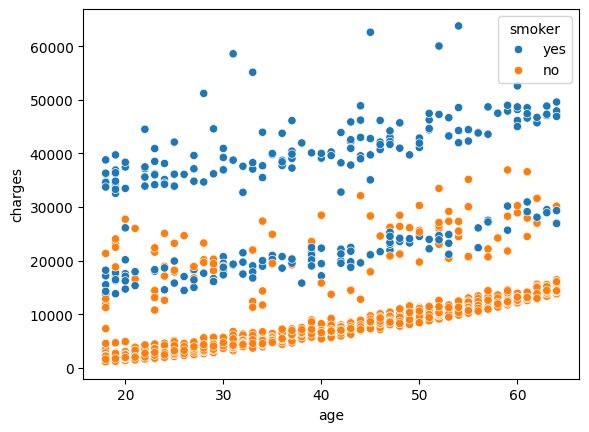

In [6]:
sns.scatterplot(data=insurance_df, x="age", y="charges", hue="smoker")

In [7]:
#Feature Engineering
X = insurance_df.drop(columns=["charges", "region"])
y = insurance_df["charges"]
print("independent variables: ", X.columns)
print("dependent variable: ", y.name)
X['sex'] = X['sex'].map({'male': 0, 'female': 1})
X['smoker'] = X['smoker'].map({'yes': 1, 'no': 0})
X.head()

independent variables:  Index(['age', 'sex', 'bmi', 'children', 'smoker'], dtype='object')
dependent variable:  charges


,age,sex,bmi,children,smoker
0,19,1,27.900,0,1
1,18,0,33.770,1,0
2,28,0,33.000,3,0
3,33,0,22.705,0,0
4,32,0,28.880,0,0


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [9]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
X_train

,age,sex,bmi,children,smoker
560,46,1,19.950,2,0
1285,47,1,24.320,0,0
1142,52,1,24.860,0,0
969,39,1,34.320,5,0
486,54,1,21.470,3,0
...,...,...,...,...,...
1095,18,1,31.350,4,0
1130,39,1,23.870,5,0
1294,58,0,25.175,0,0
860,37,1,47.600,2,1


In [11]:
model.coef_, model.intercept_

(array([2.57068962e+02, 7.95178837e+00, 3.27533514e+02, 4.27254431e+02,
        2.36539033e+04]),
 np.float64(-12121.403039282892))

In [12]:
print(f"Intercept: {model.intercept_}")
for feature, coef in zip(X_train.columns, model.coef_):
    print(f"{feature}: {coef}")

Intercept: -12121.403039282892
age: 257.068962278136
sex: 7.951788365801576
bmi: 327.5335135360793
children: 427.2544305093686
smoker: 23653.903314741205


In [13]:
y_pred = model.predict(X_test)
y_pred

array([ 8554.81711589,  6973.58746745, 36798.60416104,  9417.88282303,
       26871.68031081, 11097.38383938,   145.27608963, 16746.1683771 ,
         747.53414191, 11153.67590722, 28518.15016561,  9292.18345421,
        5460.51975119, 38510.48013003, 40359.30938604, 37223.40538064,
       15316.56711945, 36047.50032223,  9326.29049907, 31400.1559532 ,
        4269.64414373, 10464.66374097,  2719.9260555 ,  6579.53742551,
       11232.00255515, 12472.06793446, 14807.11281089,  6066.19283362,
        9535.69029723,  2377.6983797 ,  9475.05690885, 12963.23366722,
        4706.09057393,  3414.674504  ,  4815.64981654, 12484.17176954,
        2359.13614479,  9161.02061228, 33238.67621442, 32743.41702445,
        4274.58967205,  4229.5442107 , 14435.36485176, 11384.66898976,
        8925.70468583, 12480.09178788,  5154.45787816,  3554.10047649,
       35649.60942684,  9276.25523701, 15971.35991397,  2552.75200479,
       12162.99980138,  1062.65132285, 13551.43771934, 12103.65505529,
      

In [14]:
y_test

764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64

In [15]:
y_pred_train = model.predict(X_train)
X_train['Predicted Charges'] = y_pred_train
X_train['Actual Charges'] = y_train
X_train.head(10)

,age,sex,bmi,children,smoker,Predicted Charges,Actual Charges
560,46,1,19.950,2,0,7100.523470,9193.83850
1285,47,1,24.320,0,0,7934.405025,8534.67180
1142,52,1,24.860,0,0,9396.617934,27117.99378
969,39,1,34.320,5,0,11289.460615,8596.82780
486,54,1,21.470,3,0,10082.180539,12475.35130
170,63,0,41.470,0,0,17656.756391,13405.39030
277,22,1,24.300,0,0,1501.130298,2150.46900
1033,18,0,21.565,0,1,23223.001816,13747.87235
209,40,0,41.230,1,0,12092.816645,6610.10970
947,37,0,34.200,1,1,32672.952473,39047.28500


In [16]:
X_test['Predicted Charges'] = y_pred
X_test['Actual Charges'] = y_test
X_test.head(10)

,age,sex,bmi,children,smoker,Predicted Charges,Actual Charges
764,45,1,25.175,2,0,8554.817116,9095.06825
887,36,1,30.020,0,0,6973.587467,5272.17580
890,64,1,26.885,0,1,36798.604161,29330.98315
1293,46,0,25.745,3,0,9417.882823,9301.89355
259,19,0,31.920,0,1,26871.680311,33750.29180
1312,34,0,42.900,1,0,11097.383839,4536.25900
899,19,1,22.515,0,0,145.276090,2117.33885
752,64,0,37.905,0,0,16746.168377,14210.53595
1286,28,1,17.290,0,0,747.534142,3732.62510
707,49,0,28.690,3,0,11153.675907,10264.44210


In [17]:
for i in range(len(X_test)):
    y = model.intercept_
    for feature, coef in zip(X.columns, model.coef_):
        y += coef * X_test[feature].iloc[i]
    print(f"Total Predicted Charges: {y}")

Total Predicted Charges: 8554.817115888563
Total Predicted Charges: 6973.587467448905
Total Predicted Charges: 36798.60416104231
Total Predicted Charges: 9417.882823025831
Total Predicted Charges: 26871.680310814547
Total Predicted Charges: 11097.3838393809
Total Predicted Charges: 145.27608963231887
Total Predicted Charges: 16746.1683771029
Total Predicted Charges: 747.5341419095275
Total Predicted Charges: 11153.675907223993
Total Predicted Charges: 28518.15016561083
Total Predicted Charges: 9292.183454208087
Total Predicted Charges: 5460.519751190808
Total Predicted Charges: 38510.48013003363
Total Predicted Charges: 40359.309386042834
Total Predicted Charges: 37223.40538064437
Total Predicted Charges: 15316.567119450174
Total Predicted Charges: 36047.50032223246
Total Predicted Charges: 9326.290499073557
Total Predicted Charges: 31400.155953201454
Total Predicted Charges: 4269.644143729645
Total Predicted Charges: 10464.663740971877
Total Predicted Charges: 2719.9260554985012
Total

In [18]:
#Evaluation of the model input
from sklearn.metrics import mean_squared_error, r2_score
r2_input = r2_score(y_train, y_pred_train)
print("R-squared (input): ", r2_input)


n = X_train.shape[0]  # number of observations
p = X_train.shape[1]  # number of predictors
adjusted_r2_input = 1 - (1 - r2_input) * (n - 1) / (n - p - 1)
print("Adjusted R-squared (input): ", adjusted_r2_input)

R-squared (input):  0.7410888590280913
Adjusted R-squared (input):  0.7393822884190486


In [19]:
#Evaluation of the model output

from sklearn.metrics import mean_squared_error, r2_score
r2 = r2_score(y_test, y_pred)
print("R-squared: ", r2)

n = X_test.shape[0]  # number of observations
p = X_test.shape[1]  # number of predictors

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print("Adjusted R-squared: ", adjusted_r2)

R-squared:  0.7811302113434095
Adjusted R-squared:  0.7752375631872706


In [17]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Mean Squared Error: ", mse)
print("Root Mean Squared Error: ", rmse)

Mean Squared Error:  33979257.05080821
Root Mean Squared Error:  5829.17293025419


In [18]:
#Feature Engineering
X = insurance_df.drop(columns=["charges"])
y = insurance_df["charges"]
X = pd.get_dummies(X, columns=["region","sex","smoker"], drop_first=True,dtype=int)  # Convert categorical variables to dummy variables
print("independent variables: ", X.columns)
print("dependent variable: ", y.name)
X.head()

independent variables:  Index(['age', 'bmi', 'children', 'region_northwest', 'region_southeast',
       'region_southwest', 'sex_male', 'smoker_yes'],
      dtype='object')
dependent variable:  charges


,age,bmi,children,region_northwest,region_southeast,region_southwest,sex_male,smoker_yes
0,19,27.900,0,0,0,1,0,1
1,18,33.770,1,0,1,0,1,0
2,28,33.000,3,0,1,0,1,0
3,33,22.705,0,1,0,0,1,0
4,32,28.880,0,1,0,0,1,0


In [19]:
from sklearn.linear_model import LinearRegression
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
X.columns

Index(['age', 'bmi', 'children', 'region_northwest', 'region_southeast',
       'region_southwest', 'sex_male', 'smoker_yes'],
      dtype='object')

In [20]:
model.coef_, model.intercept_

(array([ 2.56975706e+02,  3.37092552e+02,  4.25278784e+02, -3.70677326e+02,
        -6.57864297e+02, -8.09799354e+02, -1.85916916e+01,  2.36511289e+04]),
 np.float64(-11931.219050326681))

In [21]:
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print("R-squared: ", r2)

R-squared:  0.7835929767120724


In [22]:
X['bmi_smoker_interaction'] = X['bmi'] * X['smoker_yes']
X['age_smoker_interaction'] = X['age'] * X['smoker_yes']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print("R-squared: ", r2)

R-squared:  0.8652316979531681


In [1]:
# underfit & Overfit
# r2 training is low & r2 testing is also low - underfitting
# r2 training is high & r2 testing is low - overfitting

y_pred_train = model.predict(X_train)
r2_train = r2_score(y_train, y_pred_train)

print("R-squared (training): ", r2_train)
print("R-squared (testing): ", r2)

NameError: name 'model' is not defined